# El tratamiento de las variables categoricas

In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv("../datasets/ecom-expense/Ecom Expense.csv")

In [3]:
df.head()

,Transaction ID,Age,Items,Monthly Income,Transaction Time,Record,Gender,City Tier,Total Spend
0,TXN001,42,10,7313,627.668127,5,Female,Tier 1,4198.385084
1,TXN002,24,8,17747,126.904567,3,Female,Tier 2,4134.976648
2,TXN003,47,11,22845,873.469701,2,Male,Tier 2,5166.614455
3,TXN004,50,11,18552,380.219428,7,Female,Tier 1,7784.447676
4,TXN005,60,2,14439,403.374223,2,Female,Tier 2,3254.160485


In [4]:
dummy_gender = pd.get_dummies(df["Gender"], prefix = "Gender")
dummy_city_tier = pd.get_dummies(df["City Tier"], prefix = "City")

In [5]:
dummy_gender.head()

,Gender_Female,Gender_Male
0,True,False
1,True,False
2,False,True
3,True,False
4,True,False


In [6]:
dummy_city_tier.head()

,City_Tier 1,City_Tier 2,City_Tier 3
0,True,False,False
1,False,True,False
2,False,True,False
3,True,False,False
4,False,True,False


In [7]:
column_names = df.columns.values.tolist()
column_names

['Transaction ID',
 'Age ',
 ' Items ',
 'Monthly Income',
 'Transaction Time',
 'Record',
 'Gender',
 'City Tier',
 'Total Spend']

In [8]:
df_new = df[column_names].join(dummy_gender)
column_names = df_new.columns.values.tolist()
df_new.head()

,Transaction ID,Age,Items,Monthly Income,Transaction Time,Record,Gender,City Tier,Total Spend,Gender_Female,Gender_Male
0,TXN001,42,10,7313,627.668127,5,Female,Tier 1,4198.385084,True,False
1,TXN002,24,8,17747,126.904567,3,Female,Tier 2,4134.976648,True,False
2,TXN003,47,11,22845,873.469701,2,Male,Tier 2,5166.614455,False,True
3,TXN004,50,11,18552,380.219428,7,Female,Tier 1,7784.447676,True,False
4,TXN005,60,2,14439,403.374223,2,Female,Tier 2,3254.160485,True,False


In [9]:
df_new = df_new[column_names].join(dummy_city_tier)
df_new.head()

,Transaction ID,Age,Items,Monthly Income,Transaction Time,Record,Gender,City Tier,Total Spend,Gender_Female,Gender_Male,City_Tier 1,City_Tier 2,City_Tier 3
0,TXN001,42,10,7313,627.668127,5,Female,Tier 1,4198.385084,True,False,True,False,False
1,TXN002,24,8,17747,126.904567,3,Female,Tier 2,4134.976648,True,False,False,True,False
2,TXN003,47,11,22845,873.469701,2,Male,Tier 2,5166.614455,False,True,False,True,False
3,TXN004,50,11,18552,380.219428,7,Female,Tier 1,7784.447676,True,False,True,False,False
4,TXN005,60,2,14439,403.374223,2,Female,Tier 2,3254.160485,True,False,False,True,False


In [35]:
feature_cols = ["Monthly Income", "Transaction Time", 
                "Gender_Female", "Gender_Male", 
                "City_Tier 1", "City_Tier 2", "City_Tier 3",
                "Record"]

In [36]:
X = df_new[feature_cols]
Y = df_new["Total Spend"]

In [37]:
lm = LinearRegression()
lm.fit(X,Y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [38]:
print(lm.intercept_)
print(lm.coef_)

-79.41713030136634
[ 1.47538980e-01  1.54946125e-01 -1.31025013e+02  1.31025013e+02
  7.67643260e+01  5.51389743e+01 -1.31903300e+02  7.72233446e+02]


In [39]:
list(zip(feature_cols, lm.coef_))

[('Monthly Income', np.float64(0.14753898049205744)),
 ('Transaction Time', np.float64(0.154946125495895)),
 ('Gender_Female', np.float64(-131.02501325554587)),
 ('Gender_Male', np.float64(131.02501325554593)),
 ('City_Tier 1', np.float64(76.76432601049535)),
 ('City_Tier 2', np.float64(55.138974309232545)),
 ('City_Tier 3', np.float64(-131.9033003197279)),
 ('Record', np.float64(772.2334457445633))]

In [40]:
lm.score(X,Y)

0.9179923586131016

El modelo puede ser escrito como:
* Total_Spend = -79.41713030136634 + 'Monthly Income' * 0.14753898049205744 +
      'Transaction Time' * 0.154946125495895 + 'Gender_Female' * -131.02501325554587 +
      'Gender_Male' * 131.02501325554593 + 'City_Tier 1' * 76.76432601049535 +
        'City_Tier 2' * 55.138974309232545 + 'City_Tier 3' * -131.9033003197279 + 'Record' * 772.2334457445633
  
* Si es hombre y vive en CT1: Total_Spend = -79.41713030136634 + 'Monthly Income' * 0.14753898049205744 +
      'Transaction Time' * 0.154946125495895 + 131.02501325554593 + 76.76432601049535 + 'Record' * 772.2334457445633
  
* Si es hombre y vive en CT2: Total_Spend = -79.41713030136634 + 'Monthly Income' * 0.14753898049205744 +
      'Transaction Time' * 0.154946125495895 + 131.02501325554593 + 55.138974309232545 + 'Record' * 772.2334457445633

* Si es hombre y vive en CT3: Total_Spend = -79.41713030136634 + 'Monthly Income' * 0.14753898049205744 +
      'Transaction Time' * 0.154946125495895 + 131.02501325554593 - 131.9033003197279 + 'Record' * 772.2334457445633

* Si es mujer y vive en CT1: Total_Spend = -79.41713030136634 + 'Monthly Income' * 0.14753898049205744 +
      'Transaction Time' * 0.154946125495895 - 131.02501325554593 + 76.76432601049535 + 'Record' * 772.2334457445633

* Si es mujer y vive en CT2: Total_Spend = -79.41713030136634 + 'Monthly Income' * 0.14753898049205744 +
      'Transaction Time' * 0.154946125495895 - 131.02501325554593 + 55.138974309232545 + 'Record' * 772.2334457445633

* Si es mujer y vive en CT3: Total_Spend = -79.41713030136634 + 'Monthly Income' * 0.14753898049205744 +
      'Transaction Time' * 0.154946125495895 - 131.02501325554593 - 131.9033003197279 + 'Record' * 772.2334457445633

In [67]:
-79.41713030136634  + 131.02501325554593 +  - 131.02501325554593 

-79.41713030136634

In [43]:
df_new["prediction"] = -79.41713030136634 + \
    df_new['Monthly Income'] * 0.14753898049205744 + \
    df_new['Transaction Time'] * 0.154946125495895 + \
    df_new['Gender_Female'] * -131.02501325554587 + \
    df_new['Gender_Male'] * 131.02501325554593 + \
    df_new['City_Tier 1'] * 76.76432601049535 + \
    df_new['City_Tier 2'] * 55.138974309232545 + \
    df_new['City_Tier 3'] * -131.9033003197279 + \
    df_new['Record'] * 772.2334457445633

In [44]:
df_new.head()

,Transaction ID,Age,Items,Monthly Income,Transaction Time,Record,Gender,City Tier,Total Spend,Gender_Female,Gender_Male,City_Tier 1,City_Tier 2,City_Tier 3,prediction
0,TXN001,42,10,7313,627.668127,5,Female,Tier 1,4198.385084,True,False,True,False,False,4903.696720
1,TXN002,24,8,17747,126.904567,3,Female,Tier 2,4134.976648,True,False,False,True,False,4799.434826
2,TXN003,47,11,22845,873.469701,2,Male,Tier 2,5166.614455,False,True,False,True,False,5157.082504
3,TXN004,50,11,18552,380.219428,7,Female,Tier 1,7784.447676,True,False,True,False,False,8068.012996
4,TXN005,60,2,14439,403.374223,2,Female,Tier 2,3254.160485,True,False,False,True,False,3581.980335


In [57]:
SSD = np.sum((df_new["prediction"] - df_new["Total Spend"]) ** 2)

In [58]:
SSD

np.float64(1517733985.3408165)

In [59]:
RSE = np.sqrt(SSD / (len(df_new) - len(feature_cols) - 1))

In [60]:
RSE

np.float64(803.1318809818166)

In [61]:
sales_mean = np.mean(df_new["Total Spend"])

In [62]:
sales_mean

np.float64(6163.176415976715)

In [63]:
error = RSE / sales_mean

In [65]:
error * 100

np.float64(13.03113568029416)

## Eliminar variables dummy redundantes

In [69]:
dummy_gender = pd.get_dummies(df["Gender"], prefix = "Gender").iloc[:,1]
dummy_gender.head()

0    False
1    False
2     True
3    False
4    False
Name: Gender_Male, dtype: bool

In [70]:
dummy_city_tier = pd.get_dummies(df["City Tier"], prefix = "City").iloc[:,1:]
dummy_city_tier.head()

,City_Tier 2,City_Tier 3
0,False,False
1,True,False
2,True,False
3,False,False
4,True,False


In [71]:
column_names = df.columns.values.tolist()
df_new = df[column_names].join(dummy_gender)
column_names = df_new.columns.values.tolist()
df_new = df_new[column_names].join(dummy_city_tier)
df_new.head()

,Transaction ID,Age,Items,Monthly Income,Transaction Time,Record,Gender,City Tier,Total Spend,Gender_Male,City_Tier 2,City_Tier 3
0,TXN001,42,10,7313,627.668127,5,Female,Tier 1,4198.385084,False,False,False
1,TXN002,24,8,17747,126.904567,3,Female,Tier 2,4134.976648,False,True,False
2,TXN003,47,11,22845,873.469701,2,Male,Tier 2,5166.614455,True,True,False
3,TXN004,50,11,18552,380.219428,7,Female,Tier 1,7784.447676,False,False,False
4,TXN005,60,2,14439,403.374223,2,Female,Tier 2,3254.160485,False,True,False


In [72]:
feature_cols = ["Monthly Income", "Transaction Time", "Gender_Male", "City_Tier 2", "City_Tier 3", "Record"]
X = df_new[feature_cols]
Y = df_new["Total Spend"]
lm = LinearRegression()
lm.fit(X,Y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [73]:
print(lm.intercept_)

-133.67781754642328


In [74]:
list(zip(feature_cols, lm.coef_))

[('Monthly Income', np.float64(0.1475389804920575)),
 ('Transaction Time', np.float64(0.1549461254958972)),
 ('Gender_Male', np.float64(262.05002651109595)),
 ('City_Tier 2', np.float64(-21.625351701262762)),
 ('City_Tier 3', np.float64(-208.66762633022321)),
 ('Record', np.float64(772.2334457445638))]

In [75]:
lm.score(X,Y)

0.9179923586131016

Coeficientes con todas las variables en el modelo
* [('Monthly Income', np.float64(0.14753898049205744)),
* ('Transaction Time', np.float64(0.154946125495895)),
* ('Gender_Female', np.float64(-131.02501325554587)),
* ('Gender_Male', np.float64(131.02501325554593)),
* ('City_Tier 1', np.float64(76.76432601049535)),
* ('City_Tier 2', np.float64(55.138974309232545)),
* ('City_Tier 3', np.float64(-131.9033003197279)),
* ('Record', np.float64(772.2334457445633))]

Coeficientes tras enmascarar las variables dummy pertinentes
* [('Monthly Income', np.float64(0.1475389804920575)),
* ('Transaction Time', np.float64(0.1549461254958972)),
* ('Gender_Male', np.float64(262.05002651109595)),
* ('City_Tier 2', np.float64(-21.625351701262762)),
* ('City_Tier 3', np.float64(-208.66762633022321)),
* ('Record', np.float64(772.2334457445638))]

Los cambios se reflejan en:
* Gender_Male:
  * Antes -> 131.02
  * despues -> 262.05 = (131.02 - (-131.02))
* Gender_Female:
   * Antes -> -131.02
   * despues -> 0 
* CT1:
   * Antes -> 76.76
   * despues -> 0
* CT2:
  * Antes -> 55.13
  * despues -> -21.62 = (55.13 - 76.76)
* CT3:
  * Antes -> -131.90
  * despues -> -208.66 = (-131.90 - 76.76)

## Transformacion de variables para conseguir una relacion no lineal

In [76]:
import pandas as pd

In [77]:
data_auto = pd.read_csv("../datasets/auto/auto-mpg.csv")
data_auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino


In [78]:
data_auto.shape

(406, 9)

In [79]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'CV vs MPG')

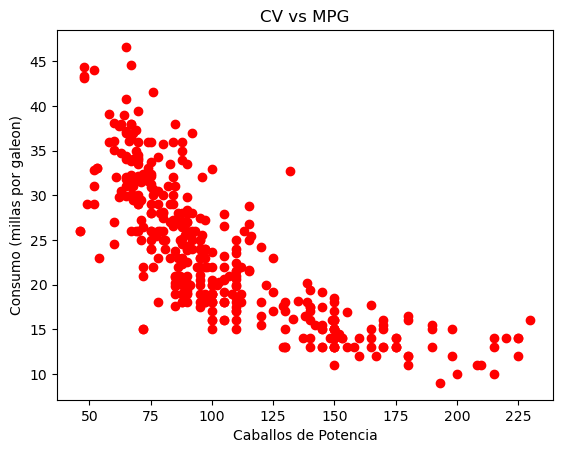

In [81]:
%matplotlib inline
data_auto["mpg"] = data_auto["mpg"].dropna()
data_auto["horsepower"] = data_auto["horsepower"].dropna()
plt.plot(data_auto["horsepower"], data_auto["mpg"], "ro")
plt.xlabel("Caballos de Potencia")
plt.ylabel("Consumo (millas por galeon)")
plt.title("CV vs MPG")

### Modelo de regresion lineal
* mpg = a + b * horsepower

In [165]:
X = data_auto[["horsepower"]].fillna(data_auto["horsepower"].mean())
Y = data_auto["mpg"].fillna(data_auto["mpg"].mean())

In [166]:
lm = LinearRegression()
lm.fit(X, Y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [167]:
type(X)

pandas.core.frame.DataFrame

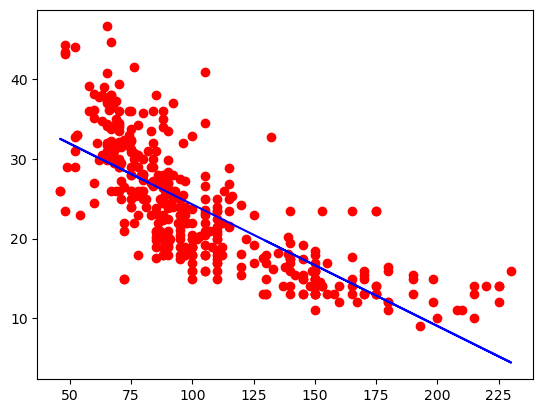

In [168]:
%matplotlib inline
plt.plot(X, Y, "ro")
plt.plot(X, lm.predict(X), color="blue")

In [151]:
lm.score(X, Y)

0.5746533406450252

In [169]:
SSD = np.sum((Y - lm.predict(X)) ** 2)
RSE = np.sqrt(SSD / (len(X) - 1))
y_mean = np.mean(Y)
error = RSE / y_mean
SSD, RSE, y_mean, error*100

(np.float64(10315.751960060918),
 np.float64(5.046879480825511),
 np.float64(23.514572864321607),
 np.float64(21.462773361633474))

### Modelo de regresion cuadratico
* mpg = a + b * horsepower^2

In [173]:
X_cuad = X**2
lm_cuad = LinearRegression()
lm_cuad.fit(X_cuad, Y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [174]:
lm_cuad.score(X_cuad, Y)

0.4849887034823206

In [176]:
SSD = np.sum((Y - lm_cuad.predict(X_cuad)) ** 2)
RSE = np.sqrt(SSD / (len(X_cuad) - 1))
y_mean = np.mean(Y)
error = RSE / y_mean
SSD, RSE, y_mean, error*100

(np.float64(12490.350340501924),
 np.float64(5.553410772769817),
 np.float64(23.514572864321607),
 np.float64(23.616889852998113))

### Modelo de regresion lineal y cuadratico
* mpg = a + b * horsepower + c * horsepower^2

In [177]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn import linear_model

In [179]:
poly = PolynomialFeatures(degree=2)

In [180]:
X_poly = poly.fit_transform(X)
lm_poly = LinearRegression()
lm_poly.fit(X_poly, Y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [181]:
print("Score Polinómico:", lm_poly.score(X_poly, Y))

Score Polinómico: 0.6439066584257469


In [182]:
lm_poly.intercept_

np.float64(55.026192447080355)

In [183]:
lm_poly.coef_

array([ 0.        , -0.43404318,  0.00112615])

$$\text{mpg} = 55.026 - 0.434 \cdot \text{horsepower} + 0.001126 \cdot \text{horsepower}^2$$

In [195]:
for d in range(2, 6):
    poly = PolynomialFeatures(degree=d)
    X_poly = poly.fit_transform(X)
    lm_poly = LinearRegression()
    lm_poly.fit(X_poly, Y)
    
    print("Regresion de grado " + str(d))
    print("R2", lm_poly.score(X_poly, Y))
    print(lm_poly.intercept_)
    print(lm_poly.coef_)
    regresion_validation(X, Y, lm_poly.predict(X_poly)) # <-- Cambio aquí
    print("-" * 40)

Regresion de grado 2
R2 0.6439066584257469
55.026192447080355
[ 0.         -0.43404318  0.00112615]
SSD: 8636.180643524502, RSE: 4.61778115803654, Y_mean: 23.514572864321607, error: 19.6379546619069%
----------------------------------------
Regresion de grado 3
R2 0.6444678885560744
58.44877411191841
[ 0.00000000e+00 -5.27113167e-01  1.89736722e-03 -1.95723195e-06]
SSD: 8622.56936742855, RSE: 4.614140736300908, Y_mean: 23.514572864321607, error: 19.622473106036686%
----------------------------------------
Regresion de grado 4
R2 0.6467674189704501
40.096643848002714
[ 0.00000000e+00  1.62563541e-01 -7.10892744e-03  4.65580255e-05
 -9.15840093e-08]
SSD: 8566.799832491355, RSE: 4.5991947315797574, Y_mean: 23.514572864321607, error: 19.55891250126879%
----------------------------------------
Regresion de grado 5
R2 0.6547512490373542
-40.69382539919788
[ 0.00000000e+00  4.00021432e+00 -7.54801920e-02  6.19621368e-04
 -2.36220932e-06  3.41982965e-09]
SSD: 8373.171391195134, RSE: 4.54692173

In [193]:
def regresion_validation(X, Y, Y_pred):
    SSD = np.sum((Y - Y_pred) ** 2)
    RSE = np.sqrt(SSD / (len(X) - 1))
    y_mean = np.mean(Y)
    error = RSE / y_mean
    print("SSD: " + str(SSD) + ", RSE: " + str(RSE) + ", Y_mean: " + str(y_mean) + ", error: " + str(error*100) + "%")

## El problema de los outliers

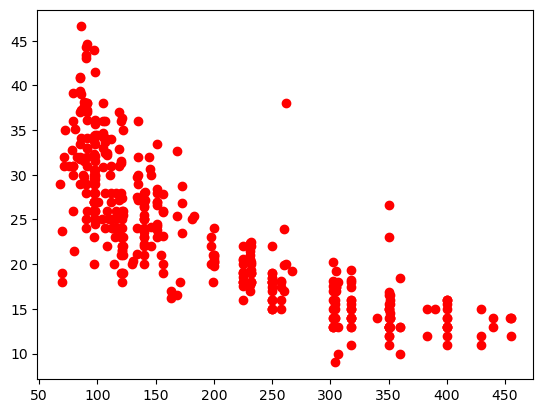

In [199]:
plt.plot(data_auto["displacement"], data_auto["mpg"], "ro")

In [203]:
X = data_auto[["displacement"]].fillna(data_auto["displacement"].mean())
Y = data_auto["mpg"].fillna(data_auto["mpg"].mean())

lm = LinearRegression()
lm.fit(X,Y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [204]:
lm.score(X,Y)

0.6261049762826918

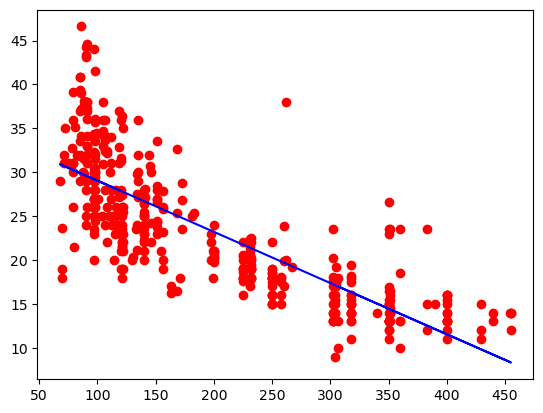

In [205]:
%matplotlib inline
plt.plot(X, Y, "ro")
plt.plot(X, lm.predict(X), color="blue")

In [210]:
data_auto[(data_auto["displacement"] > 300) & (data_auto["mpg"] > 20)]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
258,20.2,8,302.0,139.0,3570,12.8,78,1,mercury monarch ghia
305,23.0,8,350.0,125.0,3900,17.4,79,1,cadillac eldorado
372,26.6,8,350.0,105.0,3725,19.0,81,1,oldsmobile cutlass ls


In [211]:
data_auto_clean = data_auto.drop([395, 258, 305, 372])

In [212]:
X = data_auto_clean[["displacement"]].fillna(data_auto_clean["displacement"].mean())
Y = data_auto_clean["mpg"].fillna(data_auto_clean["mpg"].mean())

lm = LinearRegression()
lm.fit(X,Y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [213]:
lm.score(X,Y)

0.6466514317531822

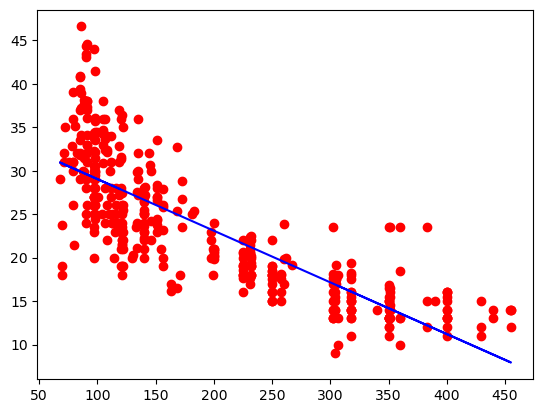

In [214]:
%matplotlib inline
plt.plot(X, Y, "ro")
plt.plot(X, lm.predict(X), color="blue")